In [1]:
import pandas as pd

df = pd.read_csv("dataset_kurma.csv")
df

,ukuran_cm,berat_g,kekerasan_N,kadar_gula_brix,kadar_air_pct,varietas,tingkat_warna,grade_cacat,stage
0,3.46,10.06,8.21,66.71,14.12,Deglet Noor,Hitam,Ringan,Tamr
1,4.68,16.50,12.21,54.79,15.34,Zahidi,Hitam,Berat,Tamr
2,4.17,9.22,82.30,21.72,67.59,Medjool,Cokelat Muda,Tidak Ada,Khalal
3,4.41,10.58,65.04,21.08,71.27,Medjool,Kuning,Sedang,Khalal
4,2.58,7.90,83.04,22.18,67.52,Ajwa,Kuning,Ringan,Khalal
...,...,...,...,...,...,...,...,...,...
1495,3.86,11.60,2.88,61.96,11.40,Medjool,Hitam,Tidak Ada,Tamr
1496,3.95,9.52,9.33,62.05,11.53,Deglet Noor,Hitam,Ringan,Tamr
1497,2.90,6.69,44.25,53.48,44.43,Medjool,Cokelat Muda,Tidak Ada,Rutab
1498,4.63,14.81,20.97,61.22,26.01,Medjool,Cokelat Tua,Sedang,Tamr


In [2]:
df.shape

(1500, 9)

In [3]:
df.columns

Index(['ukuran_cm', 'berat_g', 'kekerasan_N', 'kadar_gula_brix',
       'kadar_air_pct', 'varietas', 'tingkat_warna', 'grade_cacat', 'stage'],
      dtype='str')

In [4]:
df.describe()

,ukuran_cm,berat_g,kekerasan_N,kadar_gula_brix,kadar_air_pct
count,1500.000000,1500.000000,1455.000000,1500.000000,1500.000000
mean,3.433453,9.598580,36.581216,42.267153,45.108547
std,0.949460,3.083003,26.694869,20.951282,22.091761
min,1.620000,3.430000,2.000000,13.800000,10.050000
25%,2.710000,7.320000,11.175000,21.505000,23.385000
50%,3.360000,9.180000,32.530000,39.510000,45.175000
75%,4.050000,11.540000,58.270000,61.670000,66.170000
max,6.110000,20.100000,89.940000,82.810000,79.990000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ukuran_cm        1500 non-null   float64
 1   berat_g          1500 non-null   float64
 2   kekerasan_N      1455 non-null   float64
 3   kadar_gula_brix  1500 non-null   float64
 4   kadar_air_pct    1500 non-null   float64
 5   varietas         1500 non-null   str    
 6   tingkat_warna    1500 non-null   str    
 7   grade_cacat      1455 non-null   str    
 8   stage            1500 non-null   str    
dtypes: float64(5), str(4)
memory usage: 145.9 KB


In [34]:
df.isna().sum()

ukuran_cm          0
berat_g            0
kekerasan_N        0
kadar_gula_brix    0
kadar_air_pct      0
varietas           0
tingkat_warna      0
grade_cacat        0
stage              0
dtype: int64

In [9]:
df["varietas"].value_counts()

varietas
Ajwa           325
Medjool        324
Zahidi         306
Deglet Noor    276
Barhi          269
Name: count, dtype: int64

In [10]:
df["tingkat_warna"].value_counts()

tingkat_warna
Cokelat Muda    444
Kuning          436
Cokelat Tua     423
Hitam           197
Name: count, dtype: int64

In [29]:
df["grade_cacat"].value_counts()

grade_cacat
Ringan       675
Tidak Ada    515
Sedang       235
Berat         75
Name: count, dtype: int64

In [12]:
df["stage"].value_counts()

stage
Tamr      500
Khalal    500
Rutab     500
Name: count, dtype: int64

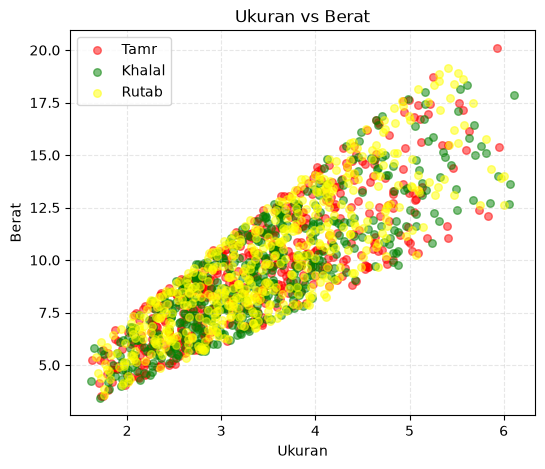

In [28]:
import matplotlib.pyplot as plt

tamr = df[df["stage"]=="Tamr"]
khalal = df[df["stage"]=="Khalal"]
rutab = df[df["stage"]=="Rutab"]

plt.figure(figsize=(6,5))

plt.scatter(tamr["ukuran_cm"], tamr["berat_g"], s=30, alpha = 0.5, color = "red", label = "Tamr")
plt.scatter(khalal["ukuran_cm"], khalal["berat_g"], s=30, alpha = 0.5, color = "green", label = "Khalal")
plt.scatter(rutab["ukuran_cm"], rutab["berat_g"], s=30, alpha = 0.5, color = "yellow", label = "Rutab")

plt.title("Ukuran vs Berat")
plt.xlabel("Ukuran")
plt.ylabel("Berat")
plt.grid(True, linestyle = "--", alpha = 0.3)
plt.legend()
plt.show()

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

X = df[['ukuran_cm', 'berat_g', 'kekerasan_N', 'kadar_gula_brix','kadar_air_pct', 'varietas', 'tingkat_warna', 'grade_cacat']]
y = df['stage']

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2, random_state=42
)

numeric_columns = ['ukuran_cm', 'berat_g', 'kekerasan_N', 'kadar_gula_brix','kadar_air_pct']
categorical_columns = ['varietas','grade_cacat']
ordinal_columns = ['grade_cacat']

cacat_order = ['Tidak Ada', 'Ringan', 'Sedang', 'Berat']
ordinal_order = [cacat_order]

preprocessing = ColumnTransformer(
    transformers = [
        ('scaler', StandardScaler(), numeric_columns),
        ('ohe', OneHotEncoder(), categorical_columns),
        ('oe', OrdinalEncoder(categories= ordinal_order), ordinal_columns)
    ]
)

model = Pipeline (
    steps=[
        ('preprocessing', preprocessing),
        ('model', LogisticRegression())
    ]
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"accuracy score :\n{accuracy_score(y_test,y_pred)}")
print(f"classification report :\n{classification_report(y_test,y_pred)}")
print(f"confusion matrix :\n{confusion_matrix(y_test,y_pred)}")

accuracy score :
1.0
classification report :
              precision    recall  f1-score   support

      Khalal       1.00      1.00      1.00       107
       Rutab       1.00      1.00      1.00       101
        Tamr       1.00      1.00      1.00        92

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300

confusion matrix :
[[107   0   0]
 [  0 101   0]
 [  0   0  92]]


In [33]:
df["kekerasan_N"] = df["kekerasan_N"].fillna(df["kekerasan_N"].mean())

In [24]:
df["grade_cacat"] = df["grade_cacat"].fillna(df["grade_cacat"].mode()[0])

In [37]:
print (df["kekerasan_N"].skew())

0.45511216515158337


In [44]:
data_baru = pd.DataFrame([[3.5,11.7, 6.7, 67.0, 55.1, 'Barhi', 'Cokelat Muda', 'Ringan' ]],
                        columns= ['ukuran_cm', 'berat_g', 'kekerasan_N', 'kadar_gula_brix','kadar_air_pct', 'varietas', 'tingkat_warna', 'grade_cacat'])
prediksi = model.predict(data_baru)[0]
presentase = max(model.predict_proba(data_baru)[0])
print(f'model memprediksi {prediksi}, dengan tingkat keyakinan {presentase*100:.2f}%')

model memprediksi Rutab, dengan tingkat keyakinan 71.65%


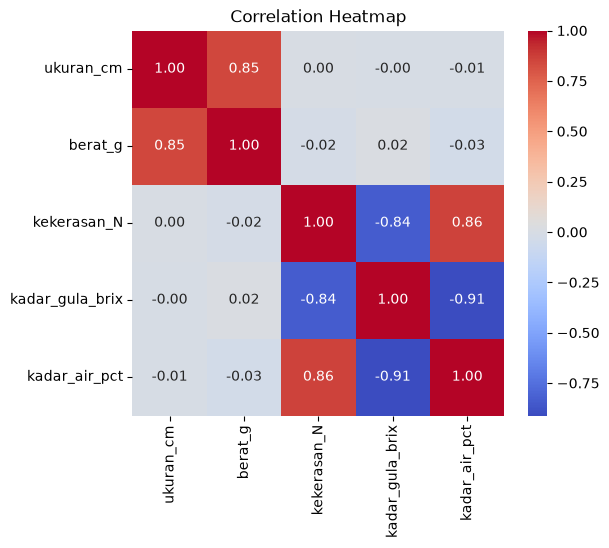

In [41]:
import seaborn as sns

corr = df.corr(numeric_only=True)

plt.figure(figsize = (6,5))
sns.heatmap(corr, annot = True, cmap="coolwarm", fmt=".2f") #viridis
plt.title("Correlation Heatmap")
plt.show()

In [45]:
df.head(5)

,ukuran_cm,berat_g,kekerasan_N,kadar_gula_brix,kadar_air_pct,varietas,tingkat_warna,grade_cacat,stage
0,3.46,10.06,8.21,66.71,14.12,Deglet Noor,Hitam,Ringan,Tamr
1,4.68,16.50,12.21,54.79,15.34,Zahidi,Hitam,Berat,Tamr
2,4.17,9.22,82.30,21.72,67.59,Medjool,Cokelat Muda,Tidak Ada,Khalal
3,4.41,10.58,65.04,21.08,71.27,Medjool,Kuning,Sedang,Khalal
4,2.58,7.90,83.04,22.18,67.52,Ajwa,Kuning,Ringan,Khalal


In [46]:
df.tail(5)

,ukuran_cm,berat_g,kekerasan_N,kadar_gula_brix,kadar_air_pct,varietas,tingkat_warna,grade_cacat,stage
1495,3.86,11.60,2.88,61.96,11.40,Medjool,Hitam,Tidak Ada,Tamr
1496,3.95,9.52,9.33,62.05,11.53,Deglet Noor,Hitam,Ringan,Tamr
1497,2.90,6.69,44.25,53.48,44.43,Medjool,Cokelat Muda,Tidak Ada,Rutab
1498,4.63,14.81,20.97,61.22,26.01,Medjool,Cokelat Tua,Sedang,Tamr
1499,2.01,4.25,18.87,63.69,15.17,Deglet Noor,Cokelat Tua,Ringan,Tamr


In [47]:
df.sample(5)

,ukuran_cm,berat_g,kekerasan_N,kadar_gula_brix,kadar_air_pct,varietas,tingkat_warna,grade_cacat,stage
443,4.33,10.03,2.17,71.45,24.26,Barhi,Cokelat Tua,Sedang,Tamr
767,2.52,9.01,76.01,19.96,71.72,Barhi,Kuning,Ringan,Khalal
319,2.45,7.40,8.84,79.43,13.58,Deglet Noor,Hitam,Ringan,Tamr
784,2.35,6.12,40.25,46.86,38.76,Deglet Noor,Cokelat Muda,Sedang,Rutab
1304,2.31,6.87,6.48,72.79,27.21,Barhi,Cokelat Tua,Sedang,Tamr


In [53]:
import joblib as jb

jb.dump(model, "model_kurma.joblib")

['model_kurma.joblib']

In [64]:
df["kadar_air_pct"].max()

np.float64(79.99)

In [65]:
df["kadar_air_pct"].min()

np.float64(10.05)